# Classical ML baseline — road patch classification

**Smart Traffic Complaint & Monitoring System · QML workstream (Avyukt)**

Task: classify a 128×128 road-surface patch as **Cracks (Road Damage)**, **Normal Road** or **Pothole** — the same three classes as Arnav's DL model.

This notebook is the classical reference the quantum classifier is compared against:

1. Load the feature table built by `qml/src/preprocessing.py`
2. Look at the data and the train/test split
3. Train Logistic Regression, SVM and Random Forest (`qml/src/classical_model.py`)
4. Evaluate on the held-out test set: accuracy, precision, recall, F1, confusion matrix

Every model is trained twice: on all **16 features**, and on the **same 8 PCA features** the 4-qubit circuit receives (fair comparison).

In [1]:
# Works from the repo root, from qml/notebooks/, or on Colab after:
#   !git clone https://github.com/anshvsingh/smart-traffic-complaint-system.git
#   %cd smart-traffic-complaint-system
#   !pip install -q -r qml/requirements.txt
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "qml" / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
QML = ROOT / "qml"
sys.path.insert(0, str(QML / "src"))
METRICS, GRAPHS = QML / "results" / "metrics", QML / "results" / "graphs"

def show(path, width=10):
    img = plt.imread(path)
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    plt.imshow(img); plt.axis("off"); plt.show()

def load(name):
    return json.loads((METRICS / f"{name}.json").read_text())
print("repo root:", ROOT)

repo root: /home/claude/smart-traffic-complaint-system


## 1. The data

1,200 patches from the *Cracks and Potholes in Road Images* dataset (details: `qml/docs/02_dataset.md`). The split is by 500 m road stretch, so near-identical neighbouring photos never end up on both sides.

In [2]:
from preprocessing import load_features, FEATURE_NAMES, CLASSES
X_train, X_test, y_train, y_test, df = load_features()
print("train:", X_train.shape, " test:", X_test.shape)
print(df.groupby(["split", "label"]).size().unstack(), "\n")
tr, te = df[df.split == "train"], df[df.split == "test"]
print("road stretches  train:", tr.group.nunique(), " test:", te.group.nunique(),
      " shared:", len(set(tr.group) & set(te.group)))
print("photos          train:", tr.image_id.nunique(), " test:", te.image_id.nunique(),
      " shared:", len(set(tr.image_id) & set(te.image_id)))

train: (900, 16)  test: (300, 16)
label  Cracks  Normal  Pothole
split                         
test      100     100      100
train     300     300      300 

road stretches  train: 111  test: 30  shared: 0
photos          train: 671  test: 226  shared: 0


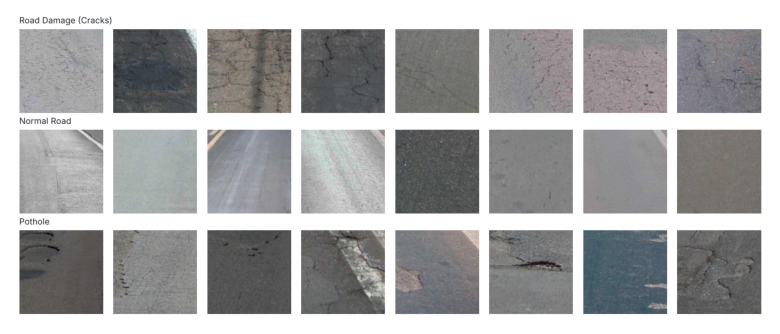

In [3]:
show(GRAPHS / "dataset_samples.png", width=11)

### Feature means per class (training set only)
Potholes are darkest; cracks and potholes have far more edges (Canny edge density) than normal road; normal road is smoother (higher GLCM homogeneity/energy).

In [4]:
print(tr.groupby("label")[FEATURE_NAMES].mean().T.round(3).to_string())

label             Cracks  Normal  Pothole
gray_mean          0.486   0.502    0.455
gray_std           0.042   0.032    0.050
gray_skew         -0.693   0.363   -0.013
dark_ratio         0.059   0.057    0.045
sobel_mean         0.030   0.020    0.026
sobel_std          0.022   0.013    0.022
edge_density       0.020   0.003    0.024
laplacian_var      0.011   0.005    0.006
glcm_contrast      2.422   1.182    1.754
glcm_homogeneity   0.641   0.730    0.697
glcm_energy        0.308   0.386    0.331
glcm_correlation   0.478   0.517    0.676
lbp_entropy        3.251   3.217    3.234
sat_mean           0.036   0.037    0.039
val_std            0.043   0.033    0.051
center_dark_diff   0.002  -0.000    0.005


## 2. Train the baselines

`classical_model.run()` does, for each model and each feature setting:

* GridSearchCV with **GroupKFold (groups = road stretch) on the training set only**, scoring = macro F1
* refit the best configuration on all 900 training patches (timed)
* predict the 300 test patches once (timed)

It takes ~30 s. The saved results in `qml/results/metrics/` were produced by exactly this call; set `RUN = True` to reproduce them (timings will differ slightly by machine).

In [5]:
RUN = False
if RUN:
    import classical_model
    classical_model.run(n_features=8)

In [6]:
rows = []
for model in ["logistic_regression", "svm_rbf", "random_forest"]:
    for setting in ["full", "reduced"]:
        m = load(f"classical_{model}_{setting}")
        rows.append({"model": model, "features": "16 (all)" if setting == "full" else "8 (PCA, same as QML)",
                     "best params": m["best_params"], "CV F1 (train)": round(m["cv_f1_macro"], 3),
                     "test accuracy": round(m["accuracy"], 3), "test precision": round(m["precision_macro"], 3),
                     "test recall": round(m["recall_macro"], 3), "test F1": round(m["f1_macro"], 3),
                     "train s": round(m["train_time_s"], 3), "infer ms/sample": round(m["inference_ms_per_sample"], 4)})
table = pd.DataFrame(rows)
print(table.drop(columns="best params").to_string(index=False))
print("\nBest by cross-validation (chosen WITHOUT looking at the test set):", load("classical_best"))

              model             features  CV F1 (train)  test accuracy  test precision  test recall  test F1  train s  infer ms/sample
logistic_regression             16 (all)          0.688          0.683           0.684        0.683    0.683    0.022           0.0014
logistic_regression 8 (PCA, same as QML)          0.651          0.650           0.651        0.650    0.650    0.011           0.0031
            svm_rbf             16 (all)          0.714          0.737           0.749        0.737    0.737    0.021           0.0190
            svm_rbf 8 (PCA, same as QML)          0.702          0.703           0.714        0.703    0.705    0.019           0.0199
      random_forest             16 (all)          0.721          0.730           0.746        0.730    0.732    0.436           0.1811
      random_forest 8 (PCA, same as QML)          0.677          0.677           0.683        0.677    0.678    0.402           0.1846

Best by cross-validation (chosen WITHOUT looking at th

CV scores (on training stretches) and test scores are close, which suggests the test estimate is honest rather than lucky. Reducing 16 → 8 features costs a few points of accuracy; that reduced setting is the fair yardstick for the 4-qubit models.

## 3. Confusion matrices of the CV-selected models

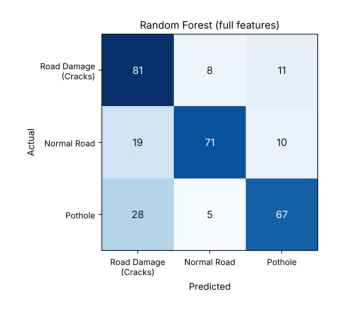

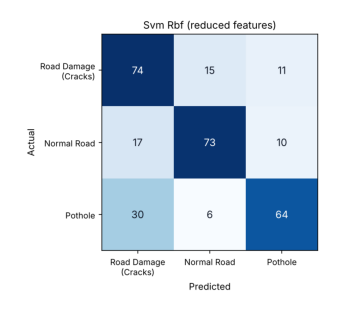

In [7]:
best = load("classical_best")
show(GRAPHS / f"cm_{best['full']}.png", width=5)
show(GRAPHS / f"cm_{best['reduced']}.png", width=5)

**Reading the matrices:** the most common mistake is a *pothole predicted as cracks* (about 30 of 100 potholes): alligator cracking and shallow potholes have similar texture at 128×128. Normal road is mostly confused with fine cracks, which are hard to see after down-scaling.

Next: `quantum_classifier.ipynb` trains the VQC on the same data and compares.